# Token Consumption & Efficacy Analysis: MH-RAG-DIVE vs. Baseline

This notebook analyzes the computational efficiency and token consumption of **MH-RAG-DIVE**. A primary focus is evaluating the impact of the **Conversation Cacher (CC)**, which utilizes semantic caching (cosine similarity on RAG response embeddings) to reuse previously validated conversational turns and reduce LLM generation costs. Another key part of the analysis is a direct comparison of token consumption against the original RAG-DIVE baseline.

## Data Preprocessing & Context
During the initial run, which established the root-node dialogues, early prototype mechanics were still active. As a result, the token measurements for the first 78 generated dialogues were inconsistent and are therefore excluded from the analysis. Consequently, the token analysis is restricted to the final 22 root dialogues. In the following sections, the term “all measurements” refers to all measurements recorded for this specific set of roots.

The IDs of these 22 valid roots are listed below. In all subsequent cache-driven evaluation runs of the MH-RAG-DIVE pipeline, the root_id was tracked to enable cross-experiment filtering and alignment with the measurements from the initial run.

The baseline token measurements from the initial run, restricted to the 22 valid roots, are stored in `metrics_20260820_130747_correct_22_roots_single_turn`.jsonl.

### Understanding Metrics Data (Token Measurements)

For every dialogue generation run, the pipeline logs key information (including token consumption) into `metrics_*.jsonl` files. To understand the preprocessing logic in the code below, it is important to clarify how this data is structured:

* **Row-Level Tracking:** Each line in a metrics file represents a single generation attempt for a specific conversational turn. This logs both successfully validated turns and *rejected* attempts (that is, when the Conversation Validator rejects a question the maximum number of times, forcing a complete regeneration of the entire dialogue).
* **Identifying Successful Dialogues:** In our experimental setup, a dialogue is always simulated over five turns. For our measurements data, this means a row belongs to a successfully generated dialogue if and only if the dialogue sequence reaches the final turn (`turn_index == 4`, representing a full 5-turn interaction) with a `status` of `"success"`. Dialogues that exhaust the retry limit and abort are logged as `"failed_and_discarded"`.

### Preprocessing Logic (Two Datasets)

Because our analysis pursues two distinct goals, the Python code below parses the metrics data into two separate arrays:

1. **Token Consumption Analysis (`data_rows_tokens`):** 
   To calculate the realistic computational cost of the framework, this dataset includes *all* recorded measurements. Token costs from successful dialogues, validation retries, and incomplete dialogues that ultimately failed and aborted are all aggregated here. This ensures that the true, total computational overhead of the pipeline is accurately reflected.

2. **Cache Hit Rate Analysis (`data_rows_hits`):** 
   For evaluating the semantic cache, this dataset isolates fully completed dialogues (those that successfully reached `turn_index == 4`). This filtering is necessary because the Pipeline relies on an all-or-nothing safeguard: aborted dialogues are discarded from the temporary memory and never committed. Thus, failed runs are not relevant for measuring cache performance.

In [9]:
import pandas as pd
import json
import glob
import os
import matplotlib.pyplot as plt

valid_root_ids = [
    "0d13ff1c-7f80-4d80-b20d-f271ce319e62", "13276015-676f-46fa-8295-a0c0d99999f9",
    "21e80181-9a6d-4e41-aab2-e39d472a1af0", "24f22bb1-d768-49c7-8884-ccaee7b75f21",
    "30bf15f8-1e83-49f6-8990-41860d783482", "349639e9-bcbc-4787-9313-377f651a0e64",
    "392b617c-0ef8-4dec-872d-db139b44641e", "3ac8618a-408a-43d9-a0ff-270068a2c4e4",
    "5314ae48-75e7-4423-881b-483e6ada2bbb", "59e03276-c652-4137-859b-7e96432069ce",
    "71cb75a1-a4b6-44af-829e-e039426c9aa8", "72326522-aeca-4b74-a1ce-3b8761ebb0c3",
    "738ef297-c100-416d-b719-e9034f3a969a", "7e457e00-9e4f-4fb0-aec1-d8fe286bcd5c",
    "87bea888-2447-414d-b9f3-1aa12af2eaaa", "99ff264f-3121-4672-b143-8a66c7073cad",
    "b14ed62a-42c9-481f-a10f-7cd4830650c4", "b66fcaf4-cd87-4ce7-8db7-4f88f75cede2",
    "cf9a7bbe-a5ef-4772-bf17-47416d9693f4", "de259d05-1252-45c2-9948-4e8b466ba262",
    "e275664e-fbfe-496f-8aa9-9ad6e0905ac6", "ef4dfd89-2cbb-47e2-b9d1-e4d7a4c9f306"
]

path_consistency = "../data/wikipedia/mh_rag_dive/"

all_files = glob.glob(os.path.join(path_consistency, "metrics_*.jsonl"))

data_rows_tokens = [] # for token consumption analysis (all measurments including error runs)
data_rows_hits = [] # for cache hit rate analysis (includes only successful dialogue generations)

for file in all_files:
    filename = os.path.basename(file)
    if filename == "metrics_20260820_130747.jsonl":
            continue
    
    run_date_str = filename.split("metrics_")[1].split(".jsonl")[0].replace("_correct_22_roots_single_turn", "")
    is_initial_file = "correct_22_roots" in filename

    with open(file, 'r', encoding='utf-8') as f:
        file_records = [json.loads(line) for line in f if line.strip()]
        
    # Filter for the 22 valid roots
    if not is_initial_file:
        file_records = [r for r in file_records if r.get('root_id') in valid_root_ids]

    # ====================================================================
    # Data Collection (DF1): Token consumption (including rejected turns)
    # ====================================================================
    if is_initial_file:
        artificial_root_id = 1
        for r in file_records:
            data_rows_tokens.append({
                'file_date': run_date_str,
                'is_initial': is_initial_file,
                'conversation_id': r['conversation_id'],
                'root_id': f"initial_{artificial_root_id}", 
                'turn_index': r['turn_index'],
                'tokens_discoverer_in': r['tokens_discoverer_in'],
                'tokens_discoverer_out': r['tokens_discoverer_out'],
                'tokens_generator_in': r['tokens_generator_in'],
                'tokens_generator_out': r['tokens_generator_out'],
                'tokens_validator_in': r['tokens_validator_in'],
                'tokens_validator_out': r['tokens_validator_out'], 
            })
            if r.get('turn_index') == 4 and r.get('status') == 'success':
                artificial_root_id += 1
    else:
        for r in file_records:
            data_rows_tokens.append({
                'file_date': run_date_str,
                'is_initial': is_initial_file,
                'conversation_id': r['conversation_id'],
                'root_id': r.get('root_id', r['conversation_id']),
                'turn_index': r['turn_index'],
                'tokens_discoverer_in': r['tokens_discoverer_in'],
                'tokens_discoverer_out': r['tokens_discoverer_out'],
                'tokens_generator_in': r['tokens_generator_in'],
                'tokens_generator_out': r['tokens_generator_out'],
                'tokens_validator_in': r['tokens_validator_in'],
                'tokens_validator_out': r['tokens_validator_out'], 
            })

    
    current_sequence = []

    # ====================================================================
    # Data Collection (DF2): Only Successful Dialogues for cache hit rate analysis
    # ====================================================================    

    artificial_hit_id = 1
    
    for r in file_records:
        turn_idx = r.get('turn_index')
        if turn_idx == 0:
            current_sequence = [r]
        elif len(current_sequence) > 0 and turn_idx == len(current_sequence):
            current_sequence.append(r)
            
            if len(current_sequence) == 5:
                clean_root_id = f"initial_{artificial_hit_id}" if is_initial_file else current_sequence[0].get('root_id', current_sequence[0]['conversation_id'])
                if r.get('status') == 'success':
                    for rec in current_sequence:
                        data_rows_hits.append({
                            'file_date': run_date_str,
                            'is_initial': is_initial_file,
                            'conversation_id': rec['conversation_id'],
                            'root_id': clean_root_id,
                            'turn_index': rec['turn_index'],
                            'cache_hit': rec['cache_hit']
                        })
                    if is_initial_file:
                        artificial_hit_id += 1
                
                current_sequence = []
        else:
            current_sequence = []

df_tokens = pd.DataFrame(data_rows_tokens)
df_hits = pd.DataFrame(data_rows_hits)
    
df_tokens = df_tokens.sort_values(by=['file_date', 'conversation_id', 'turn_index'])

df_tokens['total_tokens'] = (
    df_tokens['tokens_discoverer_in'] + df_tokens['tokens_discoverer_out'] +
    df_tokens['tokens_generator_in'] + df_tokens['tokens_generator_out'] +
    df_tokens['tokens_validator_in'] + df_tokens['tokens_validator_out']
)

### Analysis 1: Cache Hit Rates and Cache Tree Efficiency over Time

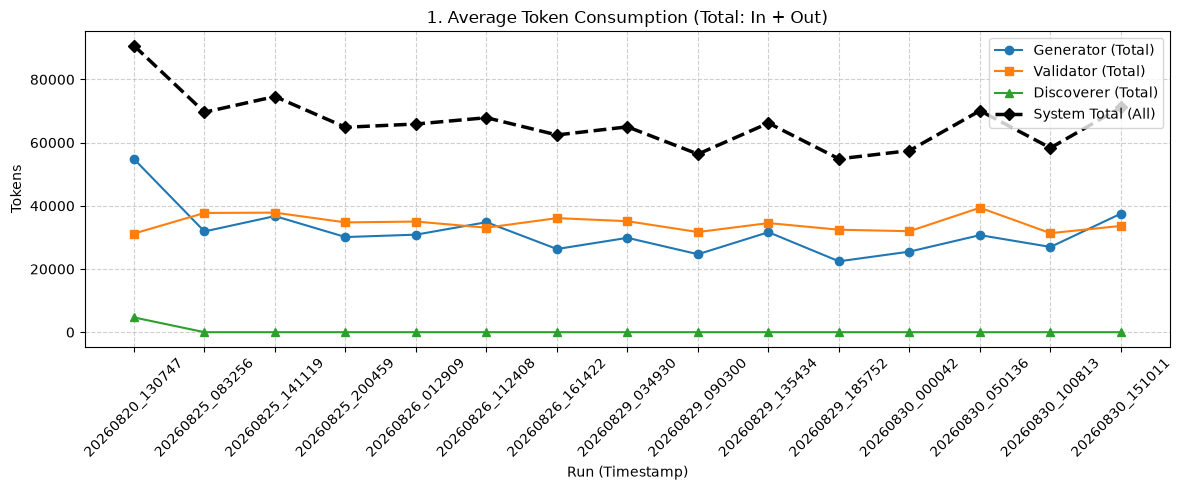

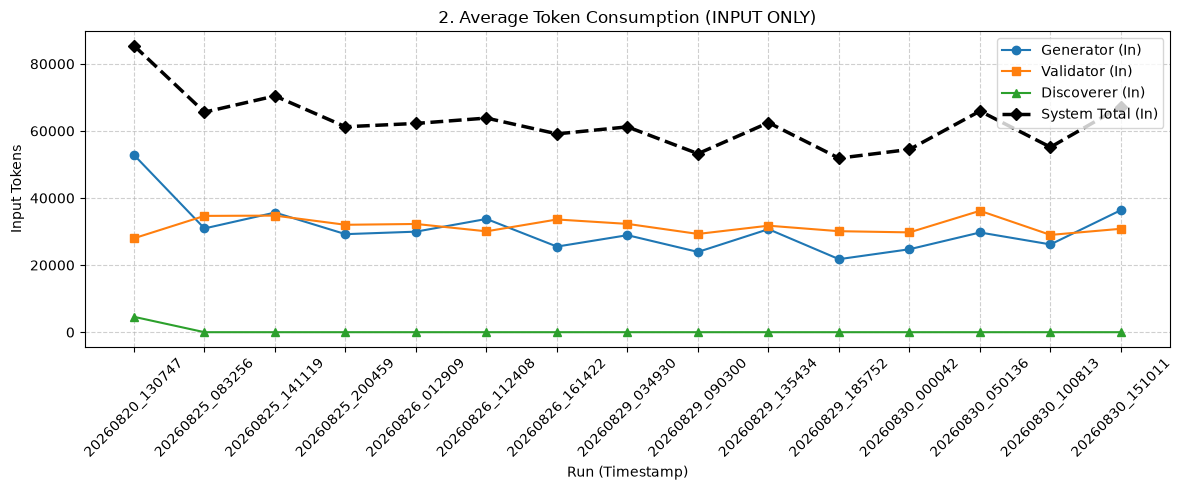

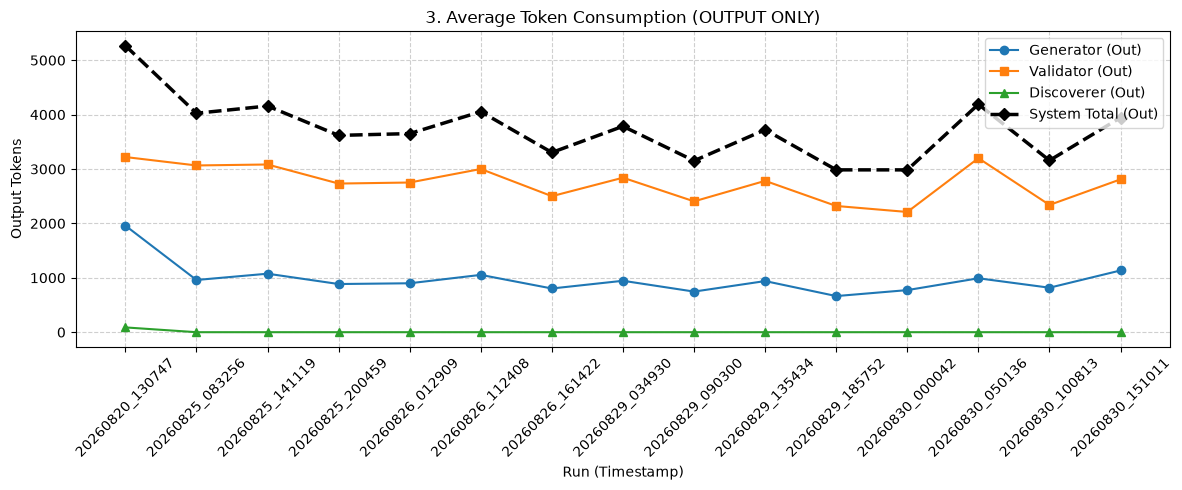


--- 2. Cache Hits per Turn (Active Cache Runs Only) ---


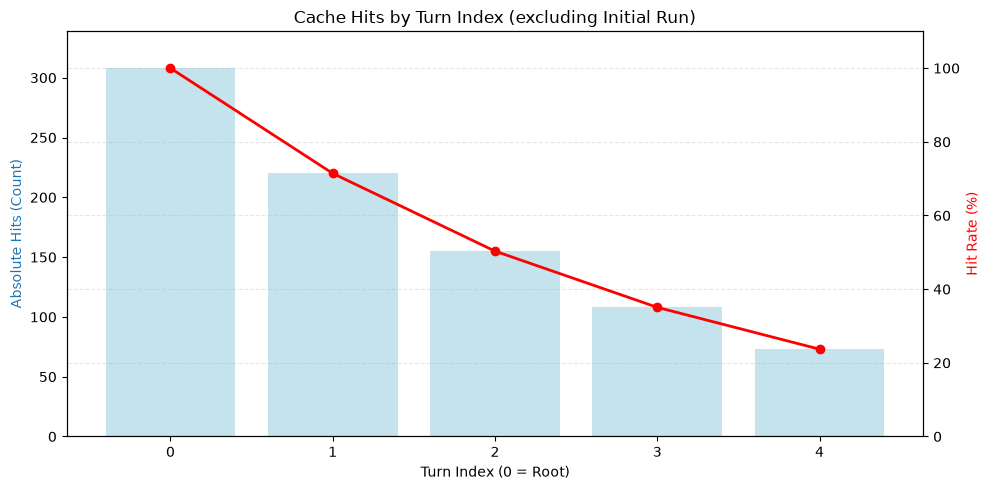

In [10]:
import matplotlib.pyplot as plt

output_dir = "plots"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

cols_to_sum = [
    'tokens_generator_in', 'tokens_generator_out',
    'tokens_validator_in', 'tokens_validator_out',
    'tokens_discoverer_in', 'tokens_discoverer_out'
]

convo_totals = df_tokens.groupby(['file_date', 'root_id'])[cols_to_sum].sum().reset_index()
run_metrics = convo_totals.groupby('file_date')[cols_to_sum].mean()

run_metrics['tokens_generator_all'] = run_metrics['tokens_generator_in'] + run_metrics['tokens_generator_out']
run_metrics['tokens_validator_all'] = run_metrics['tokens_validator_in'] + run_metrics['tokens_validator_out']
run_metrics['tokens_discoverer_all'] = run_metrics['tokens_discoverer_in'] + run_metrics['tokens_discoverer_out']

run_metrics['total_in'] = run_metrics['tokens_generator_in'] + run_metrics['tokens_validator_in'] + run_metrics['tokens_discoverer_in']
run_metrics['total_out'] = run_metrics['tokens_generator_out'] + run_metrics['tokens_validator_out'] + run_metrics['tokens_discoverer_out']
run_metrics['total_all'] = run_metrics['total_in'] + run_metrics['total_out']

x_labels = run_metrics.index

# --- PLOT 1: TOTAL TOKENS PER RUN ---
plt.figure(figsize=(12, 5))
plt.plot(x_labels, run_metrics['tokens_generator_all'], marker='o', label='Generator (Total)', color='#1f77b4')
plt.plot(x_labels, run_metrics['tokens_validator_all'], marker='s', label='Validator (Total)', color='#ff7f0e')
plt.plot(x_labels, run_metrics['tokens_discoverer_all'], marker='^', label='Discoverer (Total)', color='#2ca02c')
plt.plot(x_labels, run_metrics['total_all'], marker='D', linestyle='--', color='black', linewidth=2.5, label='System Total (All)')

plt.title('1. Average Token Consumption (Total: In + Out)')
plt.xlabel('Run (Timestamp)')
plt.ylabel('Tokens')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, '1_total_token_consumption_with_cache.png'), dpi=300, bbox_inches='tight')
plt.show()

# --- PLOT 2: INPUT TOKENS ONLY ---
plt.figure(figsize=(12, 5))
plt.plot(x_labels, run_metrics['tokens_generator_in'], marker='o', label='Generator (In)', color='#1f77b4')
plt.plot(x_labels, run_metrics['tokens_validator_in'], marker='s', label='Validator (In)', color='#ff7f0e')
plt.plot(x_labels, run_metrics['tokens_discoverer_in'], marker='^', label='Discoverer (In)', color='#2ca02c')
plt.plot(x_labels, run_metrics['total_in'], marker='D', linestyle='--', color='black', linewidth=2.5, label='System Total (In)')

plt.title('2. Average Token Consumption (INPUT ONLY)')
plt.xlabel('Run (Timestamp)')
plt.ylabel('Input Tokens')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, '2_input_token_consumption_with_cache.png'), dpi=300, bbox_inches='tight')
plt.show()

# --- PLOT 3: OUTPUT TOKENS ONLY ---
plt.figure(figsize=(12, 5))
plt.plot(x_labels, run_metrics['tokens_generator_out'], marker='o', label='Generator (Out)', color='#1f77b4')
plt.plot(x_labels, run_metrics['tokens_validator_out'], marker='s', label='Validator (Out)', color='#ff7f0e')
plt.plot(x_labels, run_metrics['tokens_discoverer_out'], marker='^', label='Discoverer (Out)', color='#2ca02c')
plt.plot(x_labels, run_metrics['total_out'], marker='D', linestyle='--', color='black', linewidth=2.5, label='System Total (Out)')

plt.title('3. Average Token Consumption (OUTPUT ONLY)')
plt.xlabel('Run (Timestamp)')
plt.ylabel('Output Tokens')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, '3_output_token_consumption_with_cache.png'), dpi=300, bbox_inches='tight')
plt.show()

# ==============================================================================
# METRIC 2: Cache Hits per Turn
# ==============================================================================
print("\n--- 2. Cache Hits per Turn (Active Cache Runs Only) ---")

df_active_cache = df_hits[df_hits['is_initial'] == False]

cache_stats = df_active_cache.groupby('turn_index')['cache_hit'].agg(['sum', 'count'])
cache_stats['hit_rate_percent'] = (cache_stats['sum'] / cache_stats['count']) * 100
cache_stats = cache_stats.rename(columns={'sum': 'Absolute Hits', 'count': 'Total Queries'})

max_queries = cache_stats['Total Queries'].iloc[0]

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

ax1.bar(cache_stats.index, cache_stats['Absolute Hits'], color='lightblue', label='Absolute Hits', alpha=0.7)
ax2.plot(cache_stats.index, cache_stats['hit_rate_percent'], color='red', marker='o', linewidth=2, label='Hit Rate (%)')

ax1.set_xlabel('Turn Index (0 = Root)')
ax1.set_ylabel('Absolute Hits (Count)', color='tab:blue')
ax2.set_ylabel('Hit Rate (%)', color='red')
plt.title('Cache Hits by Turn Index (excluding Initial Run)')
ax1.set_xticks(cache_stats.index)

ax1.set_ylim(0, max_queries * 1.1)
ax2.set_ylim(0, 100 * 1.1)
# ---------------------------------------

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, '4_cache_hits_per_turn_cleaned.png'), dpi=300, bbox_inches='tight')
plt.show()


In [8]:
cache_stats.head()

,Absolute Hits,Total Queries,hit_rate_percent
turn_index,,,
0,308,308,100.000000
1,220,308,71.428571
2,155,308,50.324675
3,108,308,35.064935
4,73,308,23.701299


### Analysis 2: Token Consumption Comparision with RAG-DIVE

--- Baseline Sanity Check ---
       file_date  success_count
0  20260828_1125            100
1  20260828_1649            100
2  20260828_0604            100
3  20260827_1933            100
4  20260827_1402            100
5  20260828_0104             99
------------------------------


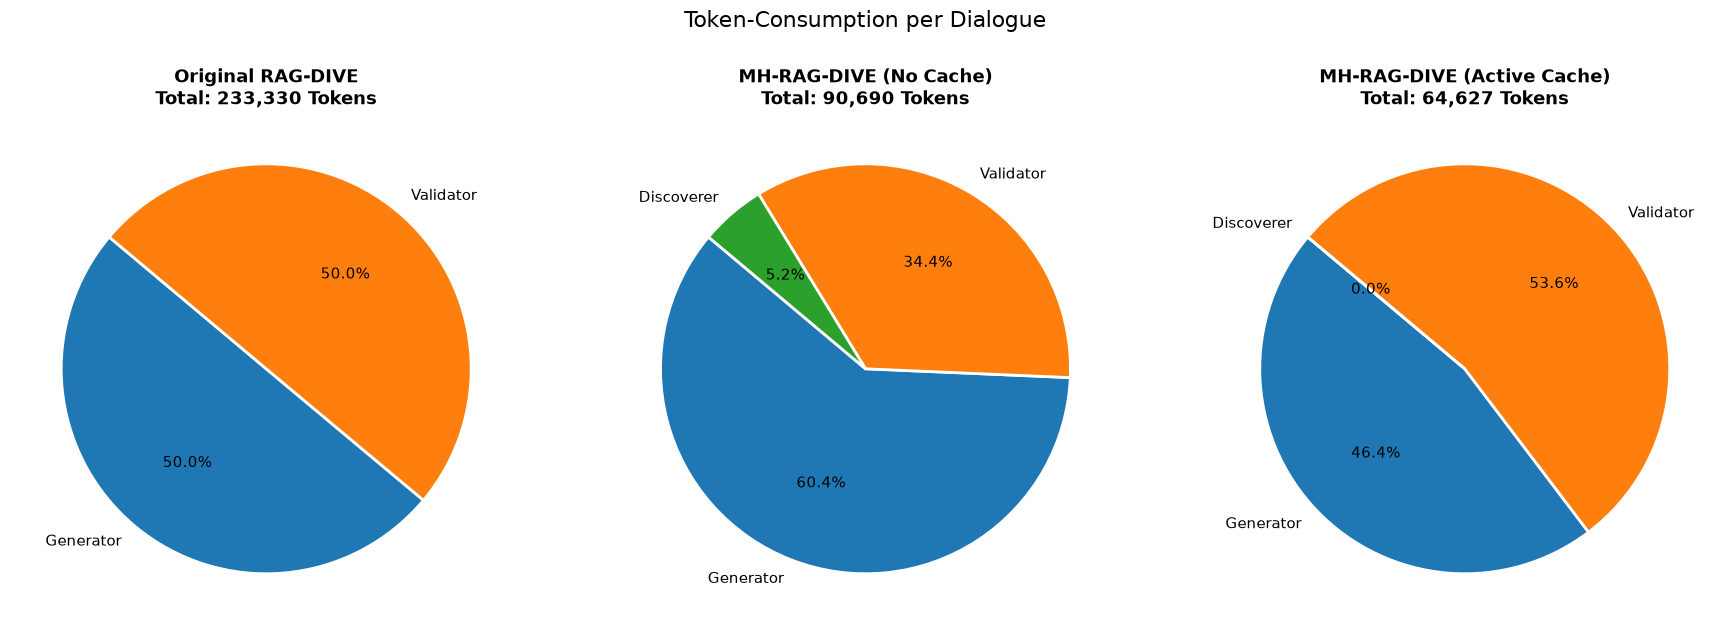

In [13]:
import pandas as pd
import json
import glob
import os
import matplotlib.pyplot as plt

output_dir = "plots"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

path_base = "../data/wikipedia/rag_dive_baseline/"
baseline_files = glob.glob(os.path.join(path_base, "*_metrics.jsonl"))

# ==============================================================================
# 1. READ BASELINE MEASUREMENTS (Incl. Failed Attempts) and Calculate Costs / Dialogue
# ==============================================================================
data_rows_baseline = []

for file in baseline_files:
    filename = os.path.basename(file)
    run_date_str = filename.split("RAG_DIVE_")[1].split("_metrics.jsonl")[0]
    
    with open(file, 'r', encoding='utf-8') as f:
        file_records = [json.loads(line) for line in f if line.strip()]

    # calculate number of successful dialogues of every RAG-DIVE run
    success_count = sum(1 for r in file_records if r.get('turn_index') == 4 and r.get('status') == 'success')
    
    if success_count == 0: 
        continue
    gen_in = sum(r.get('tokens_generator_in', 0) for r in file_records)
    gen_out = sum(r.get('tokens_generator_out', 0) for r in file_records)
    val_in = sum(r.get('tokens_validator_in', 0) for r in file_records)
    val_out = sum(r.get('tokens_validator_out', 0) for r in file_records)
    
    data_rows_baseline.append({
        'file_date': run_date_str,
        'success_count': success_count,
        'avg_gen': (gen_in + gen_out) / success_count,
        'avg_val': (val_in + val_out) / success_count
    })

df_base = pd.DataFrame(data_rows_baseline)

print("--- Baseline Sanity Check ---")
print(df_base[['file_date', 'success_count']])
print("-" * 30)

base_avg_gen = df_base['avg_gen'].mean()
base_avg_val = df_base['avg_val'].mean()
base_avg_disc = 0 # Baseline hat keinen Discoverer
base_total = base_avg_gen + base_avg_val + base_avg_disc

# ==============================================================================
# 2. Calculate Costs / Dialogue for MH-RAG-DIVE
# ==============================================================================

df_initial = df_tokens[df_tokens['is_initial'] == True]
df_cached = df_tokens[df_tokens['is_initial'] == False]

# MH-RAG-DIVE INITIAL (without Cache) - 22 roots -> divide measurements by 22
mh_init_gen = (df_initial['tokens_generator_in'].sum() + df_initial['tokens_generator_out'].sum()) / 22
mh_init_val = (df_initial['tokens_validator_in'].sum() + df_initial['tokens_validator_out'].sum()) / 22
mh_init_disc = (df_initial['tokens_discoverer_in'].sum() + df_initial['tokens_discoverer_out'].sum()) / 22
mh_init_total = mh_init_gen + mh_init_val + mh_init_disc

# MH-RAG-DIVE CACHED
num_cached_runs = df_cached['file_date'].nunique()
total_cached_dialogues = num_cached_runs * 22

mh_cache_gen = (df_cached['tokens_generator_in'].sum() + df_cached['tokens_generator_out'].sum()) / total_cached_dialogues
mh_cache_val = (df_cached['tokens_validator_in'].sum() + df_cached['tokens_validator_out'].sum()) / total_cached_dialogues
mh_cache_disc = (df_cached['tokens_discoverer_in'].sum() + df_cached['tokens_discoverer_out'].sum()) / total_cached_dialogues
mh_cache_total = mh_cache_gen + mh_cache_val + mh_cache_disc

# ==============================================================================
# 3. PLOT: PIE CHARTS (3 PANELS: BASELINE vs. MH-INITIAL vs. MH-CACHED)
# ==============================================================================
labels = ['Generator', 'Validator', 'Discoverer']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: Original RAG-DIVE
ax1.pie([base_avg_gen, base_avg_val], 
        labels=['Generator', 'Validator'], 
        autopct='%1.1f%%', startangle=140, colors=['#1f77b4', '#ff7f0e'], 
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}, textprops={'fontsize': 11})
ax1.set_title(f'Original RAG-DIVE\nTotal: {base_total:,.0f} Tokens', fontweight='bold', size=13)

# Panel 2: MH-RAG-DIVE (NO CACHE)
mh_init_values = [mh_init_gen, mh_init_val, mh_init_disc]
ax2.pie(mh_init_values, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors, 
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}, textprops={'fontsize': 11})
ax2.set_title(f'MH-RAG-DIVE (No Cache)\nTotal: {mh_init_total:,.0f} Tokens', fontweight='bold', size=13)

# Panel 3: MH-RAG-DIVE (ACTIVE CACHE)
mh_cache_values = [mh_cache_gen, mh_cache_val, mh_cache_disc]
ax3.pie(mh_cache_values, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors, 
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}, textprops={'fontsize': 11})
ax3.set_title(f'MH-RAG-DIVE (Active Cache)\nTotal: {mh_cache_total:,.0f} Tokens', fontweight='bold', size=13)

plt.suptitle('Token-Consumption per Dialogue', size=16, y=1.05)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, '6_total_token_comparison_pie_plot.png'), dpi=300, bbox_inches='tight')
plt.show()

In [14]:
# ==============================================================================
# 4. TEXT-OUTPUT-STATS (Average Token Consumption per Dialogue)
# ==============================================================================
print("\n" + "="*60)
print(" AVERAGE TOKEN CONSUMPTION PER DIALOGUE")
print(" (Including overhead from failed attempts/rejections)")
print("="*60)

print(f"\n1. ORIGINAL RAG-DIVE (Baseline)")
print(f"   Generator:  {base_avg_gen:,.0f}")
print(f"   Validator:  {base_avg_val:,.0f}")
print(f"   Discoverer: {base_avg_disc:,.0f}")
print(f"   ---------------------------")
print(f"   TOTAL:      {base_total:,.0f} Tokens")

print(f"\n2. MH-RAG-DIVE (Initial / Without Cache)")
print(f"   Generator:  {mh_init_gen:,.0f}")
print(f"   Validator:  {mh_init_val:,.0f}")
print(f"   Discoverer: {mh_init_disc:,.0f}")
print(f"   ---------------------------")
print(f"   TOTAL:      {mh_init_total:,.0f} Tokens")

print(f"\n3. MH-RAG-DIVE (With Active Cache)")
print(f"   Generator:  {mh_cache_gen:,.0f}")
print(f"   Validator:  {mh_cache_val:,.0f}")
print(f"   Discoverer: {mh_cache_disc:,.0f}")
print(f"   ---------------------------")
print(f"   TOTAL:      {mh_cache_total:,.0f} Tokens")

ersparnis_zu_baseline = 100 - (mh_cache_total / base_total * 100)
ersparnis_zu_initial = 100 - (mh_cache_total / mh_init_total * 100)

print("\n" + "-"*60)
print(" SUMMARY OF SAVINGS (Generator System):")
print(f" MH-RAG-DIVE (Cached) saves {ersparnis_zu_initial:.1f}% compared to MH-RAG-DIVE without cache.")
print(f" MH-RAG-DIVE (Cached) saves {ersparnis_zu_baseline:.1f}% compared to the RAG-DIVE Baseline.")
print("="*60 + "\n")


 AVERAGE TOKEN CONSUMPTION PER DIALOGUE
 (Including overhead from failed attempts/rejections)

1. ORIGINAL RAG-DIVE (Baseline)
   Generator:  116,731
   Validator:  116,599
   Discoverer: 0
   ---------------------------
   TOTAL:      233,330 Tokens

2. MH-RAG-DIVE (Initial / Without Cache)
   Generator:  54,801
   Validator:  31,218
   Discoverer: 4,671
   ---------------------------
   TOTAL:      90,690 Tokens

3. MH-RAG-DIVE (With Active Cache)
   Generator:  30,009
   Validator:  34,618
   Discoverer: 0
   ---------------------------
   TOTAL:      64,627 Tokens

------------------------------------------------------------
 SUMMARY OF SAVINGS (Generator System):
 MH-RAG-DIVE (Cached) saves 28.7% compared to MH-RAG-DIVE without cache.
 MH-RAG-DIVE (Cached) saves 72.3% compared to the RAG-DIVE Baseline.

